**Non-Interest-Bearing Deposits (Checking)**

Economic Variables / Relevance

1. Real GDP - cumulative trend, non-stationary; use growth instead for quarterly shifts

2. Real GDP growth - directly boosts payroll deposits from higher economic activity **(*Selected*)**

3. Nominal GDP - same issue as Real GDP level; growth matters, not absolute size

4. Nominal GDP growth - captures inflation-driven higher dollar values in transactions **(*Selected*)**

5. Real disposable income - trends up forever; growth captures the action for deposits

6. Real disposable income growth - reflects inflation-adjusted increases in household income available for spending, boosting cash flow into checking accounts **(*Selected*)**

7. Nominal disposable income - non-stationary level; stick to growth for income flow effects

8. Nominal disposable income growth - includes inflation effects already captured by CPI and nominal GDP growth; redundant for checking flow analysis 

9. Unemployment rate - job losses reduce incoming payroll, shrinking average balances **(*Selected*)**

10. Consumer Price Index (Level) - raw index trends up; inflation rate is what erodes value

11. CPI inflation rate - erodes real value, but still pads nominal checking totals short-term **(*Selected*)**

12. 3-month Treasury rate - short-term alternative lures funds out when it spikes above checking's zero yield **(*Selected*)**

13. 5-year Treasury yield - too medium-term; people don't shift daily cash for 5-year locks

14. 10-year Treasury yield - long-term investment yield, irrelevant to liquid checking flow

15. BBB corporate yield - for investors chasing yield; an investment choice, not a liquidity play. Plus, it's highly collinear with 3-month Treasury and Prime (same rate environment)

16. Mortgage rate - ties to home buying, not payroll or cash flow into accounts

17. Prime rate - affects business borrowing, indirectly timing payroll deposits for small firms **(*Selected*)**

18. Dow Jones Total Stock Market Index (Level) - stock gains might inspire spending, but checking isn't an investment pool-it's spending cash 

19. House Price Index (Level) - rising homes pull equity out via loans, not from checking

20. Commercial Real Estate Price Index (Level) - business property market; no direct link to consumer checking

21. Market Volatility Index (Level) - high fear might boost cash hoarding, but it's weak, lagged, and buried in GDP/unemployment signals

In [4414]:
import pandas as pd
import numpy as np

In [4415]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4416]:
import os
os.makedirs('graphs', exist_ok=True)

In [4417]:
# Set style for plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

In [4418]:
#Load merged historic data
merged_historic = pd.read_csv('merged_historic.csv', index_col='Date', parse_dates=True)

In [4419]:
merged_historic.head()

,Non_Maturity_IB,Non_Interest_Bearing,Time_Deposits,Real GDP,Real GDP growth,Nominal GDP,Nominal GDP growth,Real disposable income,Real disposable income growth,Nominal disposable income,...,Dow Jones Total Stock Market Index (Level),House Price Index (Level),Commercial Real Estate Price Index (Level),Market Volatility Index (Level),Consumer Price Index (Level),Non_IB_Growth,Non_Mat_IB_Growth,Time_Growth,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,,,,,,,,,,,,
1991-06-30,1098276.374,454615.450,1706710.057,10029.510,3.2,6126.862,6.2,7271.400000,3.0,4474.433333,...,3545.5,75.5,104.6,20.1,135.567,NaN,NaN,NaN,0,0
1991-09-30,1125986.253,475201.761,1679959.999,10080.195,2.0,6205.937,5.3,7299.333333,1.5,4522.066667,...,3744.0,75.2,101.0,21.2,136.600,4.528291,2.523033,-1.567346,0,0
1991-12-31,1184866.053,491843.215,1613051.671,10115.329,1.4,6264.540,3.8,7356.666667,3.2,4590.566667,...,4041.1,75.0,97.6,21.9,137.733,3.501977,5.229176,-3.982733,0,0
1992-03-31,1246734.189,483989.015,1534806.930,10236.435,4.9,6363.102,6.4,7498.600000,7.9,4708.400000,...,3961.6,75.2,95.4,19.8,138.667,-1.596891,5.221530,-4.850728,0,0
1992-06-30,1265699.776,496919.561,1467776.199,10347.429,4.4,6470.763,6.9,7568.933333,3.8,4784.100000,...,3930.3,75.0,93.2,20.2,139.733,2.671661,1.521221,-4.367372,0,0


In [4420]:
# Non-Interest-Bearing deposits (endogenous variable)
y = merged_historic['Non_Interest_Bearing']

In [4421]:
print("Non-Interest-Bearing deposits Statistics")
y.describe() 

Non-Interest-Bearing deposits Statistics


count    1.310000e+02
mean     1.888082e+06
std      1.405839e+06
min      4.546155e+05
25%      7.190829e+05
50%      1.207845e+06
75%      2.983428e+06
max      5.517936e+06
Name: Non_Interest_Bearing, dtype: float64

In [4422]:
# Selected exogenous variables
exogs = ['Real GDP growth', 'Nominal GDP growth', 'Real disposable income growth', 'Unemployment rate', 'CPI inflation rate', '3-month Treasury rate', 'Prime rate', 'GFC_Dummy', 'COVID_Dummy']
X = merged_historic[exogs]


In [4423]:
print("Statistics of Economic Variables relevant to Non-Interest-Bearing deposits")
X.describe() 


Statistics of Economic Variables relevant to Non-Interest-Bearing deposits


,Real GDP growth,Nominal GDP growth,Real disposable income growth,Unemployment rate,CPI inflation rate,3-month Treasury rate,Prime rate,GFC_Dummy,COVID_Dummy
count,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000,131.000000
mean,2.633588,4.906107,2.884733,5.756489,2.580153,2.432061,5.647328,0.061069,0.061069
std,4.561943,5.151441,7.658806,1.773441,2.208251,2.073172,2.122420,0.240376,0.240376
min,-28.000000,-29.200000,-27.600000,3.500000,-8.900000,0.000000,3.300000,0.000000,0.000000
25%,1.550000,3.600000,1.350000,4.400000,1.750000,0.200000,3.300000,0.000000,0.000000
50%,2.600000,5.000000,2.800000,5.400000,2.700000,2.000000,5.200000,0.000000,0.000000
75%,4.050000,6.500000,4.300000,6.750000,3.500000,4.650000,8.000000,0.000000,0.000000
max,34.800000,39.700000,56.000000,13.000000,9.700000,6.000000,9.500000,1.000000,1.000000


In [4424]:
from statsmodels.tsa.stattools import adfuller

In [4425]:
# First difference
y_diff = y.diff().dropna()

In [4426]:
# ADF test on differenced series
adf_result_diff = adfuller(y_diff)
print(f'ADF Statistic (diff=1): {adf_result_diff[0]:.4f}')
print(f'p-value (diff=1): {adf_result_diff[1]:.4f}')
print(f'Critical Values (diff=1): {adf_result_diff[4]}')
if adf_result_diff[1] > 0.05:
    print('Still non-stationary - may need higher differencing')
else:
    print('Stationary after diff=1 (d=1 likely needed)')

ADF Statistic (diff=1): -2.5939
p-value (diff=1): 0.0943
Critical Values (diff=1): {'1%': -3.4880216384691867, '5%': -2.8867966864160075, '10%': -2.5802408234244947}
Still non-stationary - may need higher differencing


Can not reject null hypothesis, from the above stats.

Non-Interest-Bearing deposits might have a stronger trend or structural break (e.g., post-2008 growth spurt) that one difference didn’t fully flatten. This could reflect persistent income growth or policy effects (like stimulus) not yet accounted for.

In [4427]:
y_diff2 = y.diff().diff().dropna()

In [4428]:
# ADF test on double-differenced series
adf_result_diff2 = adfuller(y_diff2)
print(f'ADF Statistic (diff=2): {adf_result_diff2[0]:.4f}')
print(f'p-value (diff=2): {adf_result_diff2[1]:.10f}')
print(f'Critical Values (diff=2): {adf_result_diff2[4]}')
if adf_result_diff2[1] > 0.05:
    print('Still non-stationary - may need higher differencing')
else:
    print('Stationary after diff=2 (d=2 likely needed)')

ADF Statistic (diff=2): -6.6523
p-value (diff=2): 0.0000000051
Critical Values (diff=2): {'1%': -3.4880216384691867, '5%': -2.8867966864160075, '10%': -2.5802408234244947}
Stationary after diff=2 (d=2 likely needed)


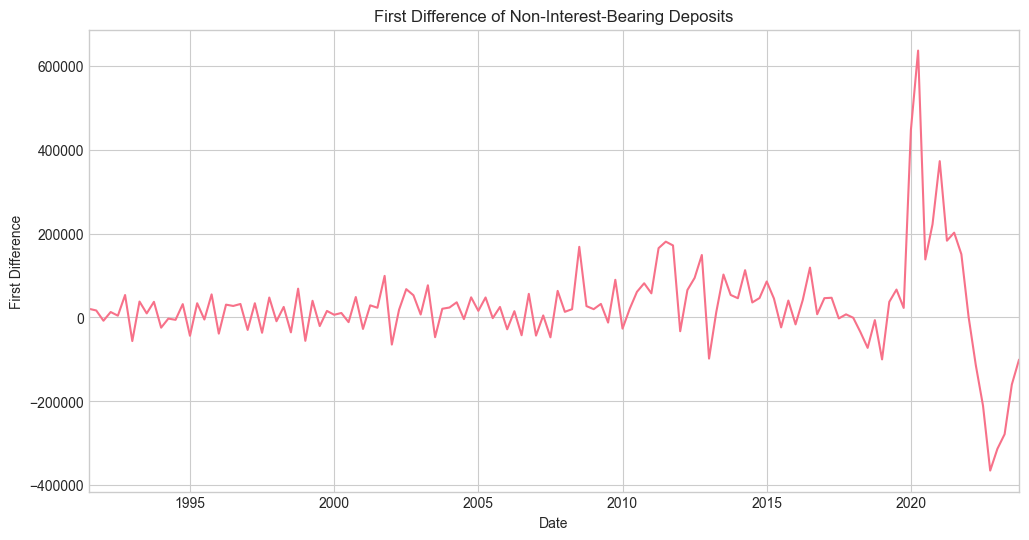

In [4429]:
plt.figure(figsize=(12, 6))
y_diff.plot(title='First Difference of Non-Interest-Bearing Deposits')
plt.ylabel('First Difference')
plt.xlabel('Date')
plt.grid(True)
plt.show()

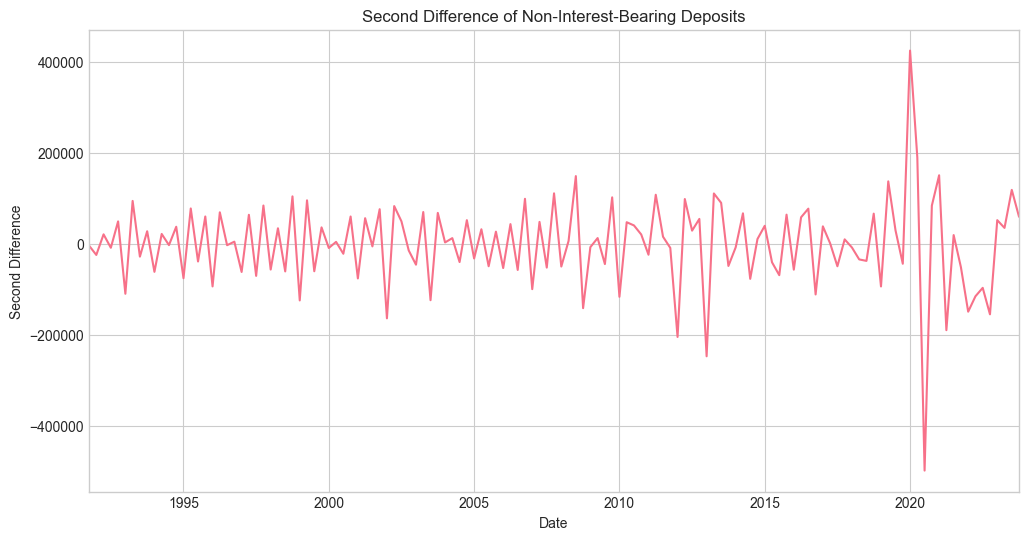

In [4430]:
plt.figure(figsize=(12, 6))
y_diff2.plot(title='Second Difference of Non-Interest-Bearing Deposits')
plt.ylabel('Second Difference')
plt.xlabel('Date')
plt.grid(True)
plt.show()

In [4431]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

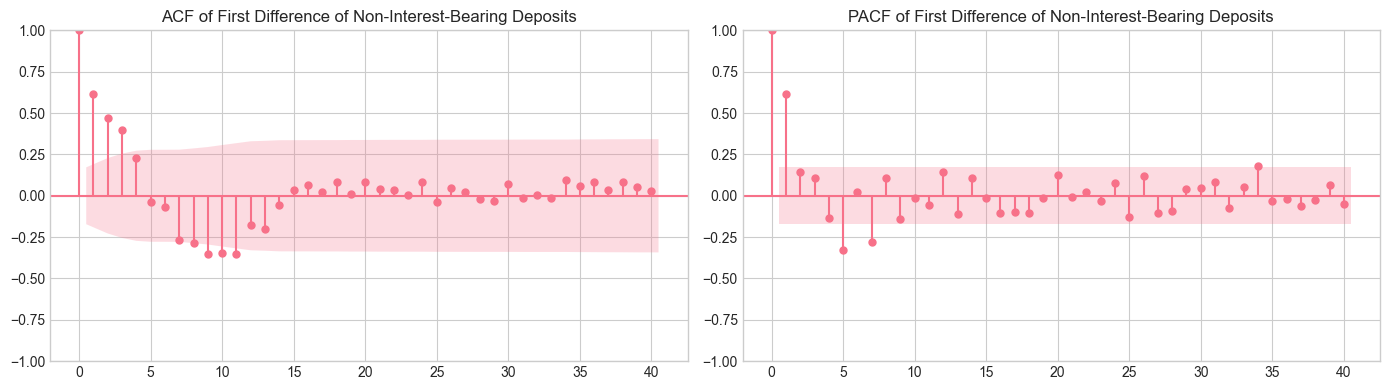

In [4432]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_diff, lags=40, ax=axes[0])
axes[0].set_title('ACF of First Difference of Non-Interest-Bearing Deposits')
plot_pacf(y_diff, lags=40, ax=axes[1], method='ywm')
axes[1].set_title('PACF of First Difference of Non-Interest-Bearing Deposits')
plt.tight_layout()
plt.savefig('graphs/non-IB/non-IB_acf_pacf.png')
plt.show()

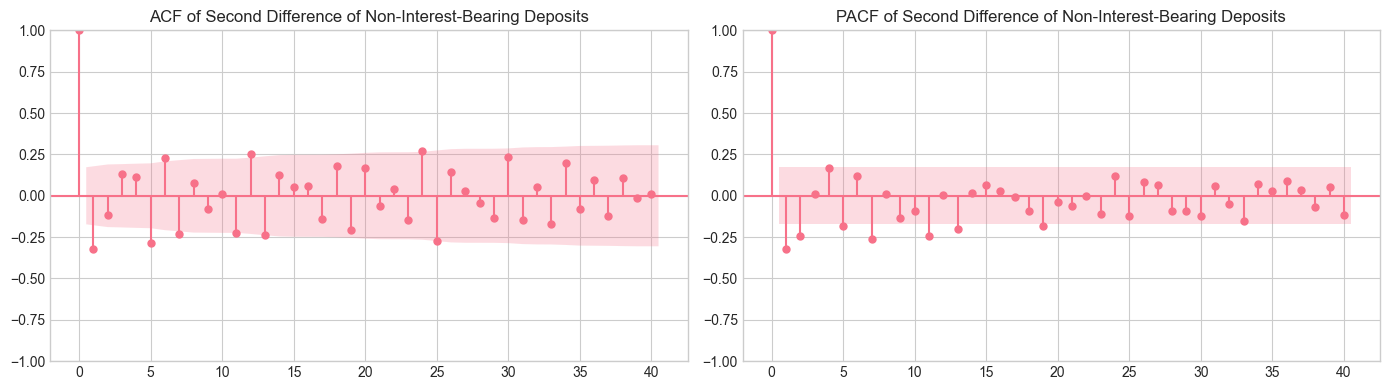

In [4433]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_diff2, lags=40, ax=axes[0])
axes[0].set_title('ACF of Second Difference of Non-Interest-Bearing Deposits')
plot_pacf(y_diff2, lags=40, ax=axes[1], method='ywm')
axes[1].set_title('PACF of Second Difference of Non-Interest-Bearing Deposits')
plt.tight_layout()
# plt.savefig('graphs/non-IB/non-IB_acf_pacf.png')
plt.show()

In [4434]:
from statsmodels.tsa.stattools import kpss

In [4435]:
# KPSS test with proper interpretation
kpss_stat, p_value, lags, critical_values = kpss(y_diff.dropna(), regression='c')

print(f"KPSS Statistic: {kpss_stat:.4f}")
print(f"P-value: {p_value:.4f} (lower bound)")
print(f"Lags used: {lags}")
print(f"Critical Values: {critical_values}")

# Better interpretation accounting for the warning
if kpss_stat < critical_values['10%']:
    print(f"KPSS: Strong evidence of stationarity (stat {kpss_stat:.4f} < 10% critical {critical_values['10%']:.3f})")
    print("Note: Actual p-value > 0.10, indicating very strong stationarity")
elif p_value > 0.05:
    print("KPSS: Series is stationary")
else:
    print("KPSS: Series is non-stationary")


KPSS Statistic: 0.0931
P-value: 0.1000 (lower bound)
Lags used: 5
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
KPSS: Strong evidence of stationarity (stat 0.0931 < 10% critical 0.347)
Note: Actual p-value > 0.10, indicating very strong stationarity


/var/folders/p2/s867_82x1zb758ysgxvlj2yw0000gn/T/ipykernel_1514/3607429990.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_stat, p_value, lags, critical_values = kpss(y_diff.dropna(), regression='c')


In [4436]:
from arch.unitroot import PhillipsPerron

In [4437]:
# Phillips–Perron test on first differenced data
pp_test = PhillipsPerron(y_diff.dropna(), lags=None, trend='c')
print(pp_test.summary())

# Access individual results
print(f"PP Statistic: {pp_test.stat:.4f}")
print(f"P-value: {pp_test.pvalue:.10f}")
print(f"Lags: {pp_test.lags}")
print(f"Critical Values: {pp_test.critical_values}")


     Phillips-Perron Test (Z-tau)    
Test Statistic                 -5.062
P-value                         0.000
Lags                               13
-------------------------------------

Trend: Constant
Critical Values: -3.48 (1%), -2.88 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.
PP Statistic: -5.0621
P-value: 0.0000166974
Lags: 13
Critical Values: {'1%': -3.482087964046026, '5%': -2.8842185101614626, '10%': -2.578864381347275}


In [4438]:
# Exclude the last two columns from X
X_no_dummies = X.iloc[:, :-2]
X_no_dummies.head()

,Real GDP growth,Nominal GDP growth,Real disposable income growth,Unemployment rate,CPI inflation rate,3-month Treasury rate,Prime rate
Date,,,,,,,
1991-06-30,3.2,6.2,3.0,6.8,2.4,5.6,8.7
1991-09-30,2.0,5.3,1.5,6.9,3.1,5.4,8.4
1991-12-31,1.4,3.8,3.2,7.1,3.4,4.5,7.6
1992-03-31,4.9,6.4,7.9,7.4,2.7,3.9,6.5
1992-06-30,4.4,6.9,3.8,7.6,3.1,3.7,6.5


In [4439]:
from statsmodels.tsa.stattools import grangercausalitytests

In [4440]:
granger_results = {}

for col in X.columns:
    if 'Dummy' in col:
        continue
    data = pd.concat([y_diff, X[col]], axis=1).dropna()
    data.columns = ['deposits', col]
    
    print(f"\nGranger Causality Test between Non-Interest-Bearing Deposits and {col}")
    # Call without the deprecated verbose argument
    test_result = grangercausalitytests(data, maxlag=4)
    
    p_values = {
        f'lag_{lag}': round(test_result[lag][0]['ssr_ftest'][1], 4)
        for lag in range(1, 5)
    }
    granger_results[col] = p_values

granger_df = pd.DataFrame(granger_results).T
print("\nGranger Causality Test Results (p-values):")
print(granger_df)

print("\nSignificant Granger causality (p < 0.05):")
for var, row in granger_df.iterrows():
    for lag, p in row.items():
        if p < 0.05:
            print(f"{var} at {lag}: p = {p}")



Granger Causality Test between Non-Interest-Bearing Deposits and Real GDP growth

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=3.7763  , p=0.0542  , df_denom=126, df_num=1
ssr based chi2 test:   chi2=3.8663  , p=0.0493  , df=1
likelihood ratio test: chi2=3.8095  , p=0.0510  , df=1
parameter F test:         F=3.7763  , p=0.0542  , df_denom=126, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=4.9966  , p=0.0082  , df_denom=123, df_num=2
ssr based chi2 test:   chi2=10.3995 , p=0.0055  , df=2
likelihood ratio test: chi2=9.9986  , p=0.0067  , df=2
parameter F test:         F=4.9966  , p=0.0082  , df_denom=123, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=3.4439  , p=0.0190  , df_denom=120, df_num=3
ssr based chi2 test:   chi2=10.9343 , p=0.0121  , df=3
likelihood ratio test: chi2=10.4890 , p=0.0148  , df=3
parameter F test:         F=3.4439  , p=0.0190  , df_denom=120, df_num=3

Granger Cau

The Granger test says, for 3-mo TSY and Prime rate, no signal : p-values never dipped below 0.05, even at lag 2-4. 

That means: even if theory sounds good (rates lure cash or delay payroll), the data doesn’t back it. Deposits didn’t twitch when rates moved. 

Could be: 

- Deposits are sticky-no one chases zero-yield savings over checking

- Payrolls for small firms aren’t rate-sensitive enough (loans fixed-term)

- Or those effects are buried-captured by GDP or unemployment instead. 

So cut Treasury and Prime. Model’s cleaner.

In [4441]:
# Original dataframe X and deposits series
# X: contains columns ['Real GDP growth', 'Nominal GDP growth', 
#                      'Real disposable income growth', 'Unemployment rate', 'CPI inflation rate', 
#                      '3-month Treasury rate', 'Prime rate',
#                      'GFC_Dummy', 'COVID_Dummy'] 
# y: non-interest-bearing deposits series

# Create lagged variables
exog_lags = pd.DataFrame({
    'Real GDP growth_lag2': X['Real GDP growth'].shift(2),
    'Nominal GDP growth_lag3': X['Nominal GDP growth'].shift(3),
    'Real disposable income growth_lag1': X['Real disposable income growth'].shift(1),
    'Unemployment rate_lag4': X['Unemployment rate'].shift(4),
    'CPI inflation rate_lag4': X['CPI inflation rate'].shift(4),
    'CPI_Level_diff': merged_historic['Consumer Price Index (Level)'].diff(),
    '3-month Treasury rate_lag1': X['3-month Treasury rate'].shift(1),
    'Prime rate_lag1': X['Prime rate'].shift(1),

    'GFC_Dummy': X['GFC_Dummy'],
    'COVID_Dummy': X['COVID_Dummy']
})

# Drop rows with NaNs from lagging
exog_final = exog_lags.dropna()

In [4442]:
exog_final.head()

,Real GDP growth_lag2,Nominal GDP growth_lag3,Real disposable income growth_lag1,Unemployment rate_lag4,CPI inflation rate_lag4,CPI_Level_diff,3-month Treasury rate_lag1,Prime rate_lag1,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,
1992-06-30,1.4,5.3,7.9,6.8,2.4,1.066,3.9,6.5,0,0
1992-09-30,4.9,3.8,3.8,6.9,3.1,1.067,3.7,6.5,0,0
1992-12-31,4.4,6.4,1.7,7.1,3.4,1.233,3.1,6.0,0,0
1993-03-31,4.0,6.9,1.8,7.4,2.7,1.034,3.1,6.0,0,0
1993-06-30,4.2,6.1,1.5,7.6,3.1,1.033,3.0,6.0,0,0


In [4443]:
exog_final.tail(15)

,Real GDP growth_lag2,Nominal GDP growth_lag3,Real disposable income growth_lag1,Unemployment rate_lag4,CPI inflation rate_lag4,CPI_Level_diff,3-month Treasury rate_lag1,Prime rate_lag1,GFC_Dummy,COVID_Dummy
Date,,,,,,,,,,
2020-06-30,2.6,5.9,2.4,3.6,2.9,-2.441,1.1,4.4,0,1
2020-09-30,-5.3,3.9,45.7,3.6,1.4,2.916,0.1,3.3,0,1
2020-12-31,-28.0,-3.5,-13.3,3.6,2.8,1.808,0.1,3.3,0,1
2021-03-31,34.8,-29.2,-7.7,3.8,1.4,2.620,0.1,3.3,0,1
2021-06-30,4.2,39.7,56.0,13.0,-3.8,4.953,0.1,3.3,0,1
2021-09-30,5.2,7.1,-27.6,8.8,4.6,4.267,0.0,3.3,0,1
2021-12-31,6.2,10.9,-5.2,6.7,2.8,5.790,0.0,3.3,0,1
2022-03-31,3.3,12.8,-5.6,6.2,4.2,6.146,0.1,3.3,0,0
2022-06-30,7.0,9.5,-9.8,5.9,7.5,6.880,0.3,3.3,0,0


In [4444]:
import statsmodels.api as sm

In [4445]:
# Ensure y and exog_final share the same DateTimeIndex

# Join on index to drop mismatches
data = pd.concat([y, exog_final], axis=1).dropna()
y_aligned = data[y.name]
exog_aligned = data[exog_final.columns]

In [4446]:
y_aligned.head()

Date
1992-06-30    496919.561
1992-09-30    501131.721
1992-12-31    554649.798
1993-03-31    498309.375
1993-06-30    536231.711
Freq: QE-DEC, Name: Non_Interest_Bearing, dtype: float64

In [4447]:
import pmdarima as pm

In [4448]:
# y_aligned: pandas Series of the target variable with DateTimeIndex
# exog_aligned: pandas DataFrame of exogenous regressors with same index

auto_model = pm.auto_arima(
    y=y_aligned,
    exogenous=exog_aligned,
    start_p=0, max_p=3,
    start_q=0, max_q=3,
    d=None,
    seasonal=True,
    m=4,              # quarterly
    start_P=0, max_P=2,
    start_Q=0, max_Q=2,
    D=None,
    information_criterion='aic',
    stepwise=True,
    trace=True,
    error_action='ignore'
    # omit n_jobs to avoid the parallel warning
)

print(auto_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,1,0)(0,0,0)[4] intercept   : AIC=3292.154, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[4] intercept   : AIC=3243.442, Time=0.02 sec
 ARIMA(0,1,1)(0,0,1)[4] intercept   : AIC=3255.751, Time=0.02 sec
 ARIMA(0,1,0)(0,0,0)[4]             : AIC=3297.544, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[4] intercept   : AIC=3244.376, Time=0.01 sec
 ARIMA(1,1,0)(2,0,0)[4] intercept   : AIC=3244.228, Time=0.03 sec
 ARIMA(1,1,0)(1,0,1)[4] intercept   : AIC=3243.061, Time=0.04 sec
 ARIMA(1,1,0)(0,0,1)[4] intercept   : AIC=3242.704, Time=0.02 sec
 ARIMA(1,1,0)(0,0,2)[4] intercept   : AIC=3243.308, Time=0.03 sec
 ARIMA(1,1,0)(1,0,2)[4] intercept   : AIC=3245.005, Time=0.05 sec
 ARIMA(0,1,0)(0,0,1)[4] intercept   : AIC=3280.492, Time=0.01 sec
 ARIMA(2,1,0)(0,0,1)[4] intercept   : AIC=3242.372, Time=0.03 sec
 ARIMA(2,1,0)(0,0,0)[4] intercept   : AIC=3242.740, Time=0.01 sec
 ARIMA(2,1,0)(1,0,1)[4] intercept   : AIC=3242.437, Time=0.06 sec
 ARIMA(2,1,0)(0,0,2)[4] intercept

#### Time series cross-validation

Anchor rolling windows around the key regime shifts rather than fixed jumps.


1992-06-30 → 1999-12-31 trains up to just before Q1 2000, tests Q1 2000–Q4 2001 (dot-com aftermath).

1994-06-30 → 2001-12-31 shifts forward 2 years, so training now covers the dot-com peak and early GFC build-up; tests Q1 2002–Q4 2003.

1999-06-30 → 2006-12-31 captures the full build-up to the GFC; tests Q1 2007–Q4 2008 (GFC onset).

2004-06-30 → 2011-12-31 trains through the GFC trough and early recovery; tests Q1 2012–Q4 2013.

2009-06-30 → 2016-12-31 starts mid-crisis recovery through the pre-COVID expansion; tests Q1 2017–Q4 2018.

2014-06-30 → 2021-06-30 trains through the COVID shock and stimulus period; tests Q3 2021–Q4 2023.

In [4449]:
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_percentage_error

In [4450]:
import matplotlib.dates as mdates

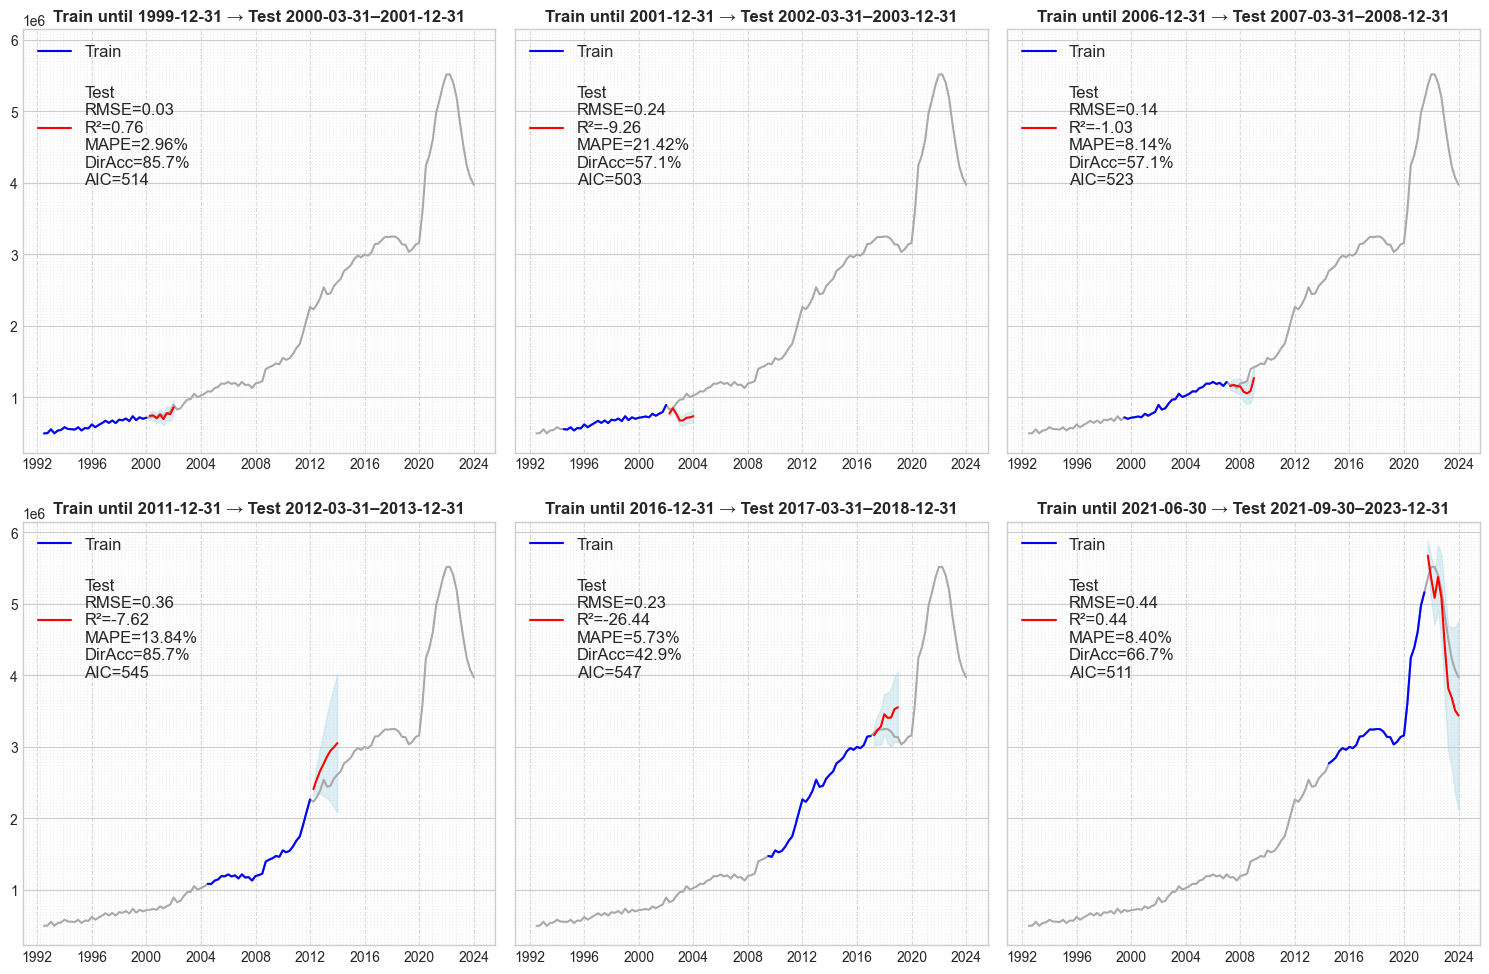

In [4451]:
# Cross-validation folds
folds = [
    # Pre-dot-com test
    ('1992-06-30', '1999-12-31', '2000-03-31', '2001-12-31'),
    # Dot-com + early GFC test
    ('1994-06-30', '2001-12-31', '2002-03-31', '2003-12-31'),
    # Run-up through the GFC test
    ('1999-06-30', '2006-12-31', '2007-03-31', '2008-12-31'),
    # GFC + early recovery test
    ('2004-06-30', '2011-12-31', '2012-03-31', '2013-12-31'),
    # Mid-cycle test before COVID
    ('2009-06-30', '2016-12-31', '2017-03-31', '2018-12-31'),
    # COVID-era test
    ('2014-06-30', '2021-06-30', '2021-09-30', '2023-12-31'),
]


def directional_accuracy(y_true, y_pred):
    return np.mean(np.sign(y_true.diff().dropna()) == np.sign(y_pred.diff().dropna())) * 100

fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharey=True)
axes = axes.flatten()

for ax, (start, train_end, test_start, test_end) in zip(axes, folds):
    # Split
    y_train = y_aligned[start:train_end]
    exog_train = exog_aligned[start:train_end]
    y_test = y_aligned[test_start:test_end]
    exog_test = exog_aligned[test_start:test_end]
    
    # Fit
    model = sm.tsa.SARIMAX(
        endog=y_train,
        exog=exog_train,
        order=(1,1,0),
        seasonal_order=(2,0,0,4),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    res = model.fit(
        disp=False,
        method='lbfgs',      # use L-BFGS optimizer
        maxiter=100000,         # increase max iterations
        # full_output=True     # ensure optimization output is shown
    )

    # Predict
    pred = res.get_prediction(start=test_start, end=test_end, exog=exog_test)
    ci = pred.conf_int(alpha=0.05)
 
    y_pred = pred.predicted_mean
    
    # Metrics
    rmse = root_mean_squared_error(y_test, y_pred)/10**6  # in millions
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    dir_acc = directional_accuracy(y_test, y_pred)
    aic = res.aic
    
    # Plot
    ax.plot(y_aligned, color='darkgray')
    ax.plot(y_train, color='blue', label='Train')
    ax.plot(
        y_test.index,
        y_pred,
        color='red',
        label=(
            f"\nTest\n"
            f"RMSE={rmse:.2f}\n"
            f"R²={r2:.2f}\n"
            f"MAPE={mape:.2%}\n"
            f"DirAcc={dir_acc:.1f}%\n"
            f"AIC={aic:.0f}"
        )
    )

    ax.legend(loc='upper left', fontsize=12, framealpha=0.9)

    ax.set_title(f'Train until {train_end} → Test {test_start}–{test_end}', fontweight='bold', fontsize=12)

    ax.fill_between(
        y_pred.index,
        ci.iloc[:, 0],
        ci.iloc[:, 1],
        color='lightblue', 
        alpha=0.4,
        label='95% CI'
    )

    # Set x-axis grid for each date (quarter)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[3, 6, 9, 12]))
    ax.grid(True, which='major', axis='x', linestyle='--', alpha=0.7)
    ax.grid(True, which='minor', axis='x', linestyle=':', alpha=0.4)
    

plt.tight_layout()
plt.savefig('graphs/non-IB/non-IB_cross_validation.png')
plt.show()

In [4452]:
y_test

Date
2021-09-30    5365297.244
2021-12-31    5516235.146
2022-03-31    5517936.329
2022-06-30    5404246.352
2022-09-30    5193729.093
2022-12-31    4828136.078
2023-03-31    4514530.179
2023-06-30    4235865.279
2023-09-30    4075738.567
2023-12-31    3974993.362
Freq: QE-DEC, Name: Non_Interest_Bearing, dtype: float64

In [4453]:
y_pred

2021-09-30    5.676550e+06
2021-12-31    5.352569e+06
2022-03-31    5.084817e+06
2022-06-30    5.376377e+06
2022-09-30    5.080858e+06
2022-12-31    4.389631e+06
2023-03-31    3.816446e+06
2023-06-30    3.692290e+06
2023-09-30    3.512040e+06
2023-12-31    3.437669e+06
Freq: QE-DEC, Name: predicted_mean, dtype: float64

In [4454]:
# Test residuals
resid_test = (y_test - y_pred).dropna()
std_resid  = (resid_test - resid_test.mean()) / resid_test.std(ddof=0)

In [4455]:
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from scipy import stats

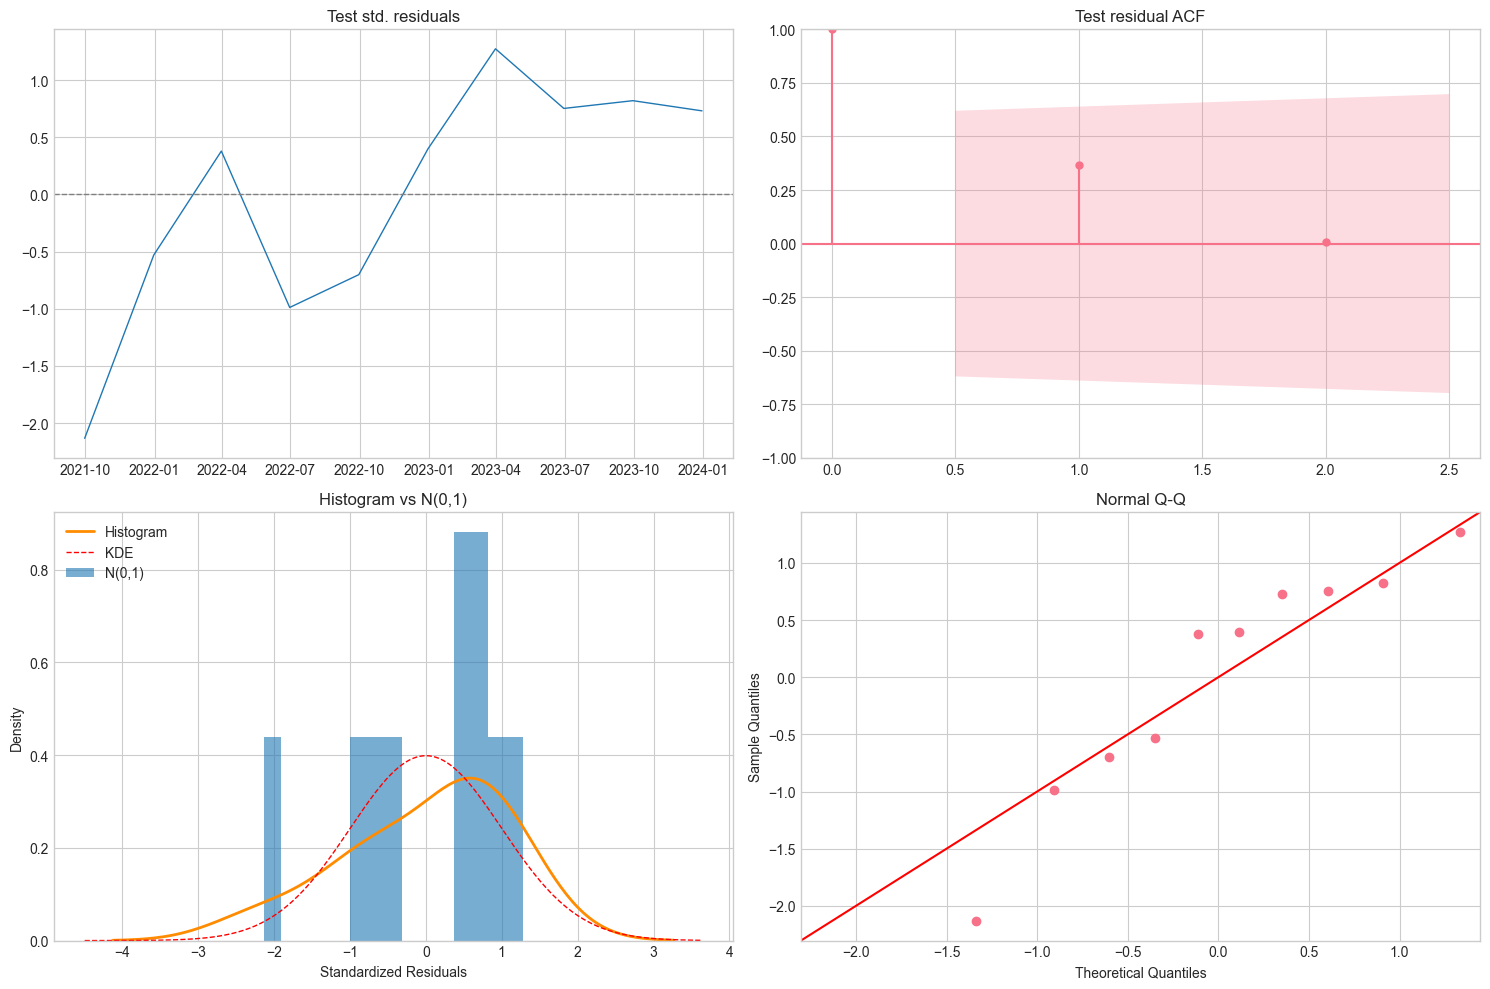

In [4456]:
# Residual diagnostics

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Residuals over time
axes[0, 0].plot(std_resid, lw=1, color='tab:blue')
axes[0, 0].axhline(0, color='gray', ls='--', lw=1)
axes[0, 0].set_title('Test std. residuals')

# ACF of standardized residuals
plot_acf(std_resid, lags=min(12, max(1, len(std_resid)//5)), ax=axes[0, 1])
axes[0, 1].set_title('Test residual ACF')

# Histogram of standardized residuals
axes[1, 0].hist(std_resid, bins=15, density=True, alpha=0.6, color='tab:blue')
sns.kdeplot(std_resid, ax=axes[1, 0], color='darkorange', lw=2) # plot kernel density estimate
xs = np.linspace(*axes[1, 0].get_xlim(), 200) # plot normal distribution for comparison
axes[1, 0].plot(xs, stats.norm.pdf(xs, 0, 1), 'r--', lw=1)
axes[1, 0].set_title('Histogram vs N(0,1)')
axes[1, 0].set_xlabel('Standardized Residuals')
axes[1, 0].set_ylabel('Density')
axes[1, 0].legend(['Histogram', 'KDE', 'N(0,1)'], loc='upper left')

# Q-Q plot of standardized residuals
sm.ProbPlot(std_resid).qqplot(line='45', ax=axes[1, 1])
axes[1, 1].set_title('Normal Q-Q')

plt.tight_layout()
plt.savefig('graphs/non-IB/non-IB_residual_diagnostics.png')
plt.show()


In [4457]:
# Statistics on test residuals

# Check residual sample size and adjust lags accordingly
n_resid = len(std_resid)
max_safe_lag = max(1, n_resid // 2 - 1)  # Ensure at least 1 lag but don't exceed sample limits
test_lags = [lag for lag in [4, 8, 12] if lag <= max_safe_lag]

if test_lags:  # Only run if we have valid lags
    lb = acorr_ljungbox(std_resid, lags=test_lags, return_df=True)
    print('Ljung–Box p-values:', {int(k): float(v) for k, v in lb['lb_pvalue'].to_dict().items()})
else:
    print(f'Sample too small (n={n_resid}) for meaningful Ljung-Box test')

jb_stat, jb_p, skew, kurt = jarque_bera(std_resid)
print(f'Jarque–Bera: stat={jb_stat:.3f}, p={jb_p:.3f}, skew={skew:.3f}, kurt={kurt:.3f}')



Ljung–Box p-values: {4: 0.6188548922974458}
Jarque–Bera: stat=1.044, p=0.593, skew=-0.762, kurt=2.573


In [4458]:
#Load scenarios data
scenarios = pd.read_csv('scenarios.csv', index_col=['Scenario Name', 'Date'], parse_dates=['Date'], date_format='%Y-%m-%d')

In [4459]:
scenarios.head()

Real GDP  Real GDP growth   Nominal GDP  \
Scenario Name        Date                                                      
Supervisory Baseline 2024-03-31  22735.953138              1.0  28180.653984   
                     2024-06-30  22775.741055              0.7  28384.963725   
                     2024-09-30  22826.986473              0.9  28604.947194   
                     2024-12-31  22912.587672              1.5  28862.391719   
                     2025-03-31  23015.694317              1.8  29158.231234   

                                 Nominal GDP growth  Real disposable income  \
Scenario Name        Date                                                     
Supervisory Baseline 2024-03-31                 3.2            16961.584792   
                     2024-06-30                 2.9            17037.911923   
                     2024-09-30                 3.1            17114.582527   
                     2024-12-31                 3.6            17200.155440   
                     2025-03-31                 4.1            17303.356372   

                                 Real disposable income growth  \
Scenario Name        Date                                        
Supervisory Baseline 2024-03-31                            2.5   
                     2024-06-30                            1.8   
                     2024-09-30                            1.8   
                     2024-12-31                            2.0   
                     2025-03-31                            2.4   

                                 Nominal disposable income  \
Scenario Name        Date                                    
Supervisory Baseline 2024-03-31               20690.266217   
                     2024-06-30               20897.168879   
                     2024-09-30               21106.140568   
                     2024-12-31               21322.478508   
                     2025-03-31               21562.356392   

                                 Nominal disposable income growth  \
Scenario Name        Date                                           
Supervisory Baseline 2024-03-31                               4.6   
                     2024-06-30                               4.0   
                     2024-09-30                               4.0   
                     2024-12-31                               4.1   
                     2025-03-31                               4.5   

                                 Unemployment rate  \
Scenario Name        Date                            
Supervisory Baseline 2024-03-31                3.9   
                     2024-06-30                4.1   
                     2024-09-30                4.2   
                     2024-12-31                4.3   
                     2025-03-31                4.3   

                                 Consumer Price Index (Level)  ...  \
Scenario Name        Date                                      ...   
Supervisory Baseline 2024-03-31                    309.931186  ...   
                     2024-06-30                    311.698122  ...   
                     2024-09-30                    313.551711  ...   
                     2024-12-31                    315.339289  ...   
                     2025-03-31                    317.059527  ...   

                                 3-month Treasury rate  5-year Treasury yield  \
Scenario Name        Date                                                       
Supervisory Baseline 2024-03-31                    5.3                    4.2   
                     2024-06-30                    5.0                    4.0   
                     2024-09-30                    4.6                    3.9   
                     2024-12-31                    4.2                    3.8   
                     2025-03-31                    3.9                    3.6   

                                 10-year Treasury yield  BBB corporate yield  \
Scenario Name        D

In [4460]:
# Use the complete historical base data X for proper lag calculation
# X contains the raw economic variables without lags
# exog_aligned contains the lagged variables used in the model

# Forecast horizon
forecast_dates = pd.date_range(start='2024-03-31', periods=13, freq='QE')
scenario_names = scenarios.index.get_level_values('Scenario Name').unique()
forecasts = {}

for scenario_name in scenario_names:
    scenario_data = scenarios.loc[scenario_name].copy()
    
    # Create complete time series combining historical X and scenario data
    # This ensures we have enough history to compute all required lags
    
    # Construct full series for each base variable
    full_series = {}
    
    # Real GDP growth: need lag 2
    full_series['Real GDP growth'] = pd.concat([
        X['Real GDP growth'],  # complete historical data
        scenario_data['Real GDP growth']  # scenario projections
    ]).drop_duplicates()
    
    # Nominal GDP growth: need lag 3  
    full_series['Nominal GDP growth'] = pd.concat([
        X['Nominal GDP growth'],
        scenario_data['Nominal GDP growth']
    ]).drop_duplicates()
    
    # Real disposable income growth: need lag 1
    full_series['Real disposable income growth'] = pd.concat([
        X['Real disposable income growth'],
        scenario_data['Real disposable income growth']
    ]).drop_duplicates()
    
    # Unemployment rate: need lag 4
    full_series['Unemployment rate'] = pd.concat([
        X['Unemployment rate'],
        scenario_data['Unemployment rate']
    ]).drop_duplicates()
    
    # CPI inflation rate: need lag 4
    full_series['CPI inflation rate'] = pd.concat([
        X['CPI inflation rate'],
        scenario_data['CPI inflation rate']
    ]).drop_duplicates()
    
    # 3-month Treasury rate: need lag 1
    full_series['3-month Treasury rate'] = pd.concat([
        X['3-month Treasury rate'],
        scenario_data['3-month Treasury rate']
    ]).drop_duplicates()
    
    # Prime rate: need lag 1
    full_series['Prime rate'] = pd.concat([
        X['Prime rate'],
        scenario_data['Prime rate']
    ]).drop_duplicates()
    
    # Now create the lagged exog matrix for forecast dates only
    scenario_X = pd.DataFrame(index=forecast_dates)
    
    # Apply lags to the full series and extract forecast period
    scenario_X['Real GDP growth_lag2'] = full_series['Real GDP growth'].shift(2).reindex(forecast_dates)
    scenario_X['Nominal GDP growth_lag3'] = full_series['Nominal GDP growth'].shift(3).reindex(forecast_dates)  
    scenario_X['Real disposable income growth_lag1'] = full_series['Real disposable income growth'].shift(1).reindex(forecast_dates)
    scenario_X['Unemployment rate_lag4'] = full_series['Unemployment rate'].shift(4).reindex(forecast_dates)
    scenario_X['CPI inflation rate_lag4'] = full_series['CPI inflation rate'].shift(4).reindex(forecast_dates)
    scenario_X['3-month Treasury rate_lag1'] = full_series['3-month Treasury rate'].shift(1).reindex(forecast_dates)
    scenario_X['Prime rate_lag1'] = full_series['Prime rate'].shift(1).reindex(forecast_dates)
    
    # CPI Level diff - compute from scenario CPI level data
    scenario_X['CPI_Level_diff'] = scenario_data['Consumer Price Index (Level)'].diff().fillna(0).reindex(forecast_dates)
    
    # Dummies (set to 0 for future periods)
    scenario_X['GFC_Dummy'] = 0
    scenario_X['COVID_Dummy'] = 0
    
    # Reorder columns to match model specification
    scenario_X = scenario_X[exog_aligned.columns]
    
    # Handle any remaining NaN values
    scenario_X = scenario_X.ffill().fillna(0)
    
    # Generate forecast using the fitted model
    forecast = res.get_forecast(steps=len(forecast_dates), exog=scenario_X)
    y_forecast = forecast.predicted_mean.clip(lower=0)
    y_forecast.index = forecast_dates
    ci = forecast.conf_int(alpha=0.05) 
    ci.index = forecast_dates
    
    forecasts[scenario_name] = {'mean': y_forecast, 'ci': ci}

In [4461]:
forecasts

{'Supervisory Baseline': {'mean': 2024-03-31    5.385438e+06
  2024-06-30    5.343196e+06
  2024-09-30    5.333025e+06
  2024-12-31    4.499713e+06
  2025-03-31    4.614314e+06
  2025-06-30    3.153987e+06
  2025-09-30    3.156957e+06
  2025-12-31    3.597824e+06
  2026-03-31    3.701096e+06
  2026-06-30    3.705148e+06
  2026-09-30    3.651708e+06
  2026-12-31    3.865876e+06
  2027-03-31    3.956808e+06
  Freq: QE-DEC, Name: predicted_mean, dtype: float64,
  'ci':             lower Non_Interest_Bearing  upper Non_Interest_Bearing
  2024-03-31                5.185655e+06                5.585222e+06
  2024-06-30                5.041212e+06                5.645181e+06
  2024-09-30                4.953419e+06                5.712632e+06
  2024-12-31                4.055611e+06                4.943815e+06
  2025-03-31                4.004769e+06                5.223859e+06
  2025-06-30                2.400771e+06                3.907204e+06
  2025-09-30                2.281694e+06        

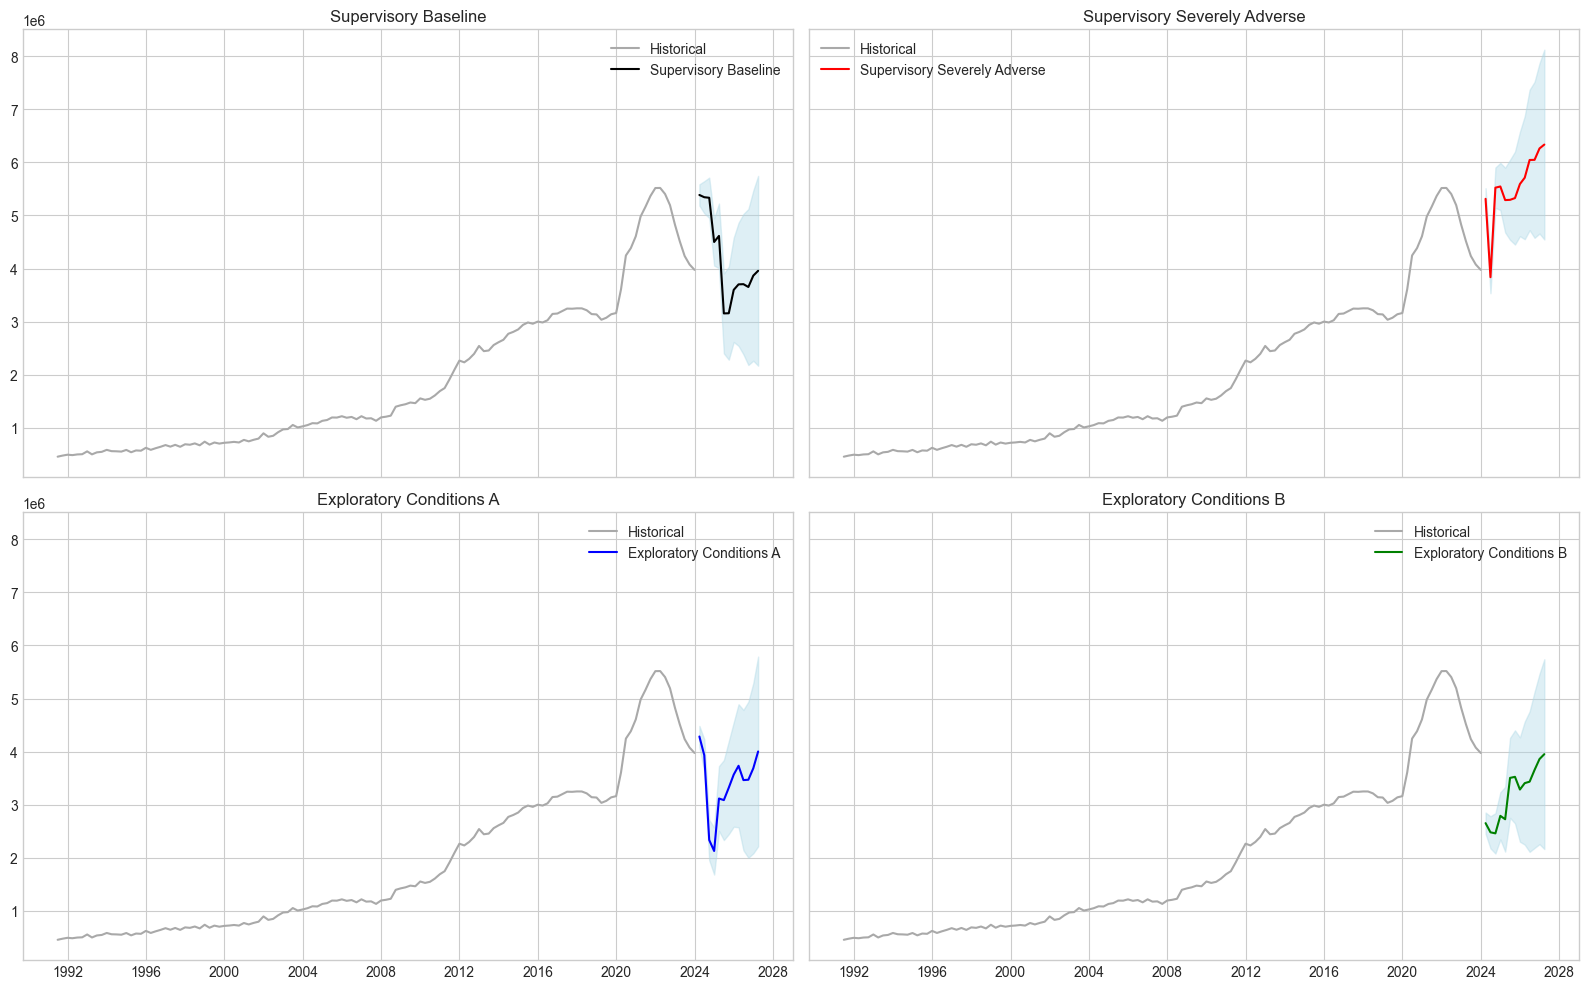

In [4462]:
# Define colors dictionary
colors = {
    'Supervisory Baseline': 'black',
    'Supervisory Severely Adverse': 'red',
    'Exploratory Conditions A': 'blue',
    'Exploratory Conditions B': 'green'
}


fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
scenario_list = list(forecasts.keys())
titles = {
    'Supervisory Baseline': 'Supervisory Baseline',
    'Supervisory Severely Adverse': 'Supervisory Severely Adverse',
    'Exploratory Conditions A': 'Exploratory Conditions A',
    'Exploratory Conditions B': 'Exploratory Conditions B'
}

for i, ax in enumerate(axes.flat):
    if i < len(scenario_list):
        scenario_name = scenario_list[i]
        forecast_data = forecasts[scenario_name]
        color = colors.get(scenario_name, 'yellow')
        
        ax.plot(y.index, y, label='Historical', color='darkgray')
        ax.plot(forecast_data['mean'].index, forecast_data['mean'], label=f'{scenario_name}', color=color)
        ax.fill_between(forecast_data['ci'].index, forecast_data['ci'].iloc[:, 0], 
                        forecast_data['ci'].iloc[:, 1], color='lightblue', alpha=0.4)
        ax.set_title(titles.get(scenario_name, scenario_name))
        ax.legend()
        ax.grid(True)
    else:
        ax.axis('off')

plt.tight_layout()
plt.savefig('graphs/non-IB/non-IB_forecasts.png', dpi=300, bbox_inches='tight')
plt.show()

**Supervisory Baseline**

- GDP growth is modest (1.0→1.9 percent) and disposable income growth stays positive (2.5→1.8 percent), while unemployment remains low (3.9→4.1 percent) and short-term rates gradually decline (3mo TSY 5.3→3.1 percent)

- Deposits dip slightly in late 2024 (reflecting rate-cut-induced portfolio shifts) then resume a gentle upward trend toward roughly $4Tn, matching steady–but-unspectacular economic expansion

**Supervisory Severely Adverse**

- A deep shock (unemployment spikes to 10 percent, stock-market collapse, 3mo Treasury plunges toward zero) leads to an initial withdrawal surge (drop to ~$3.7Tn) as firms/households draw cash

- Once immediate liquidity needs pass, a pronounced surge into deposits follows (rising to ~$6.3Tn) as risk aversion and zero yields on alternatives drive hoarding—exactly as the stress narrative implies

**Exploratory Conditions A**

A sharp but short recession (GDP growth from +0.9 percent to –11.6 percent) plus high rates (3mo TSY around 6.8 percent) pushes deposits down steeply to ~$2.2Tn

As the economy snaps back (GDP growth normalizes, rates fall), deposits rebound vigorously toward $4Tn, consistent with a swift recovery scenario

**Exploratory Conditions B**

- Prolonged weakness (GDP growth only slowly recovers, unemployment stays elevated, rates ease slowly) yields more gradual shifts: deposits rise steadily from ~$2.6Tn to ~$4Tn over three years, reflecting persistent—but not panic-inducing—flight to safety